In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml

print("MNIST Project Started!")

MNIST Project Started!


In [6]:
# Download the MNIST dataset

mnist = fetch_openml(
    name="mnist_784",
    version=1,
    as_frame=False
)

# Separate images and labels

X = mnist.data
y = mnist.target.astype(np.uint8)

print("Dataset downloaded successfully!")
print("Image data shape:", X.shape)
print("Labels shape:", y.shape)

/Users/shipandas/Desktop/ML Starter projects/.venv/lib/python3.12/site-packages/sklearn/datasets/_openml.py:95: RuntimeWarning: Invalid cache, redownloading file to /Users/shipandas/scikit_learn_data/openml/openml.org/data/v1/download/52667/mnist_784.arff.gz
  warn(


TypeError: expected string or bytes-like object, got 'int'

In [ ]:

# Download the MNIST dataset
from sklearn.datasets import fetch_openml

mnist = fetch_openml(
    name="mnist_784",
    version=1,
    as_frame=False,
    parser="liac-arff"
)

# Separate images and labels
X = mnist.data
y = mnist.target.astype("uint8")

print("Dataset downloaded successfully!")
print("Image data shape:", X.shape)
print("Labels shape:", y.shape)


Dataset downloaded successfully!
Image data shape: (70000, 784)
Labels shape: (70000,)


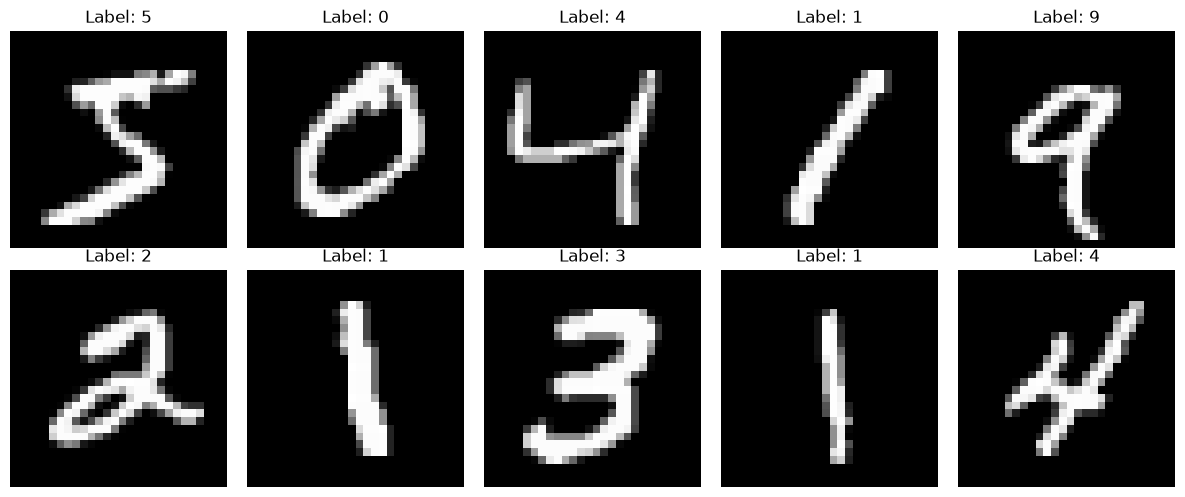

In [4]:

# Visualize some handwritten digit images

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [7]:

# Normalize pixel values

X = X.astype("float32") / 255.0

print("Normalization completed!")
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


Normalization completed!
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Data splitting completed!
Training images: (56000, 784)
Testing images: (14000, 784)


In [24]:
# Train a Random Forest model
import joblib

joblib.dump(
    model,
    "mnist_digit_model_compressed.pkl",
    compress=3
)

print("Compressed model saved successfully!")

Compressed model saved successfully!


In [10]:
# Make predictions on test data

y_pred = model.predict(X_test)

print("Predictions completed!")
print("First 10 actual labels:", y_test[:10])
print("First 10 predicted labels:", y_pred[:10])

Predictions completed!
First 10 actual labels: [7 3 1 1 2 5 9 8 8 1]
First 10 predicted labels: [7 3 1 1 2 5 9 8 8 1]


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 96.61428571428571 %


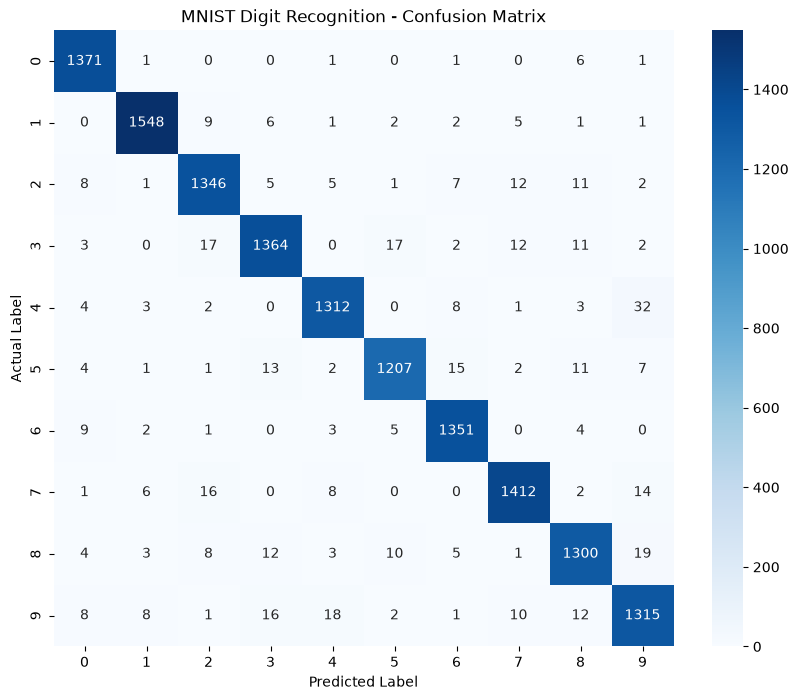

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MNIST Digit Recognition - Confusion Matrix")

plt.show()

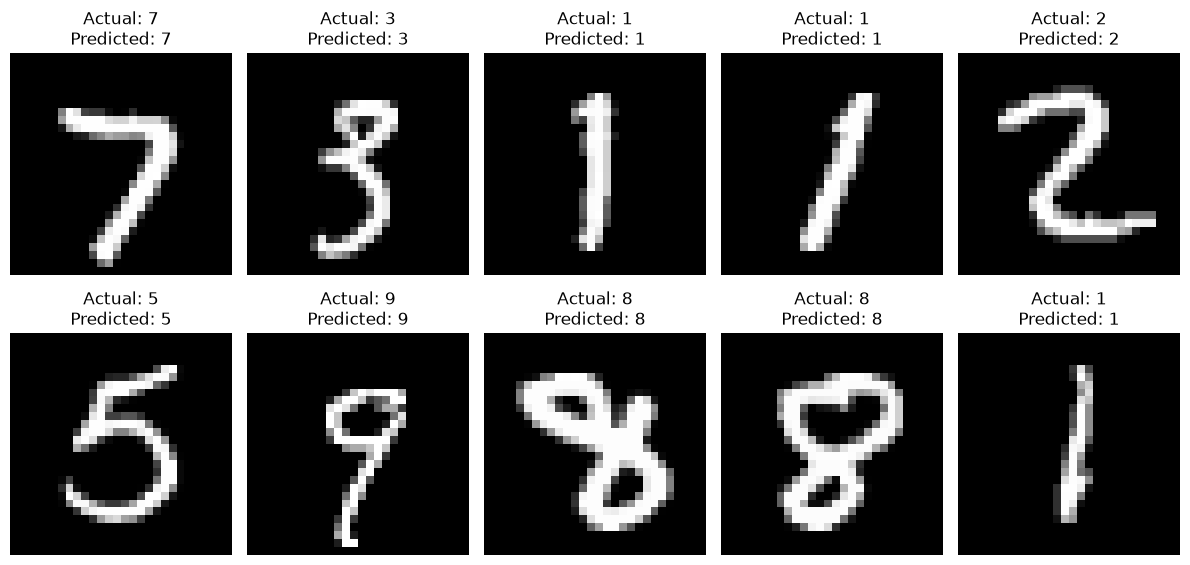

In [13]:
# Display actual vs predicted digits

import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = X_test[i].reshape(28, 28)

    plt.imshow(image, cmap="gray")

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import joblib

joblib.dump(model, "mnist_digit_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1381
           1       0.98      0.98      0.98      1575
           2       0.96      0.96      0.96      1398
           3       0.96      0.96      0.96      1428
           4       0.97      0.96      0.97      1365
           5       0.97      0.96      0.96      1263
           6       0.97      0.98      0.98      1375
           7       0.97      0.97      0.97      1459
           8       0.96      0.95      0.95      1365
           9       0.94      0.95      0.94      1391

    accuracy                           0.97     14000
   macro avg       0.97      0.97      0.97     14000
weighted avg       0.97      0.97      0.97     14000



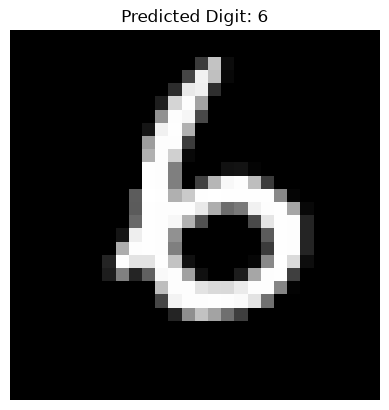

Actual Digit: 6
Predicted Digit: 6


In [16]:
import random
import matplotlib.pyplot as plt

i = random.randint(0, len(X_test) - 1)

image = X_test[i].reshape(28, 28)
prediction = model.predict(X_test[i].reshape(1, -1))

plt.imshow(image, cmap="gray")
plt.title(f"Predicted Digit: {prediction[0]}")
plt.axis("off")
plt.show()

print("Actual Digit:", y_test[i])
print("Predicted Digit:", prediction[0])

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Use a smaller training sample to keep KNN manageable
X_train_knn = X_train[:10000]
y_train_knn = y_train[:10000]

# Select a representative test sample
_, X_test_knn, _, y_test_knn = train_test_split(
    X_test,
    y_test,
    test_size=2000,
    random_state=42,
    stratify=y_test
)

# Create the KNN model
knn_model = KNeighborsClassifier(n_neighbors=3, n_jobs=-1)

# Train the model
knn_model.fit(X_train_knn, y_train_knn)

# Predict digits
knn_predictions = knn_model.predict(X_test_knn)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test_knn, knn_predictions)

print("KNN Accuracy:", knn_accuracy * 100, "%")

KNN Accuracy: 95.0 %


In [18]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

# Create the SVM model
svm_model = LinearSVC(random_state=42, max_iter=3000)

# Train using the same 10,000 training images
svm_model.fit(X_train[:10000], y_train[:10000])

# Predict using the same test sample as KNN
svm_predictions = svm_model.predict(X_test_knn)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test_knn, svm_predictions)

print("SVM Accuracy:", svm_accuracy * 100, "%")

SVM Accuracy: 88.55 %


In [19]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["KNN", "SVM", "Random Forest"],
    "Accuracy": [
        knn_accuracy,
        svm_accuracy,
        accuracy_score(
            y_test_knn,
            model.predict(X_test_knn)
        )
    ]
})

comparison["Accuracy (%)"] = comparison["Accuracy"] * 100

print(comparison[["Model", "Accuracy (%)"]])

           Model  Accuracy (%)
0            KNN         95.00
1            SVM         88.55
2  Random Forest         97.25


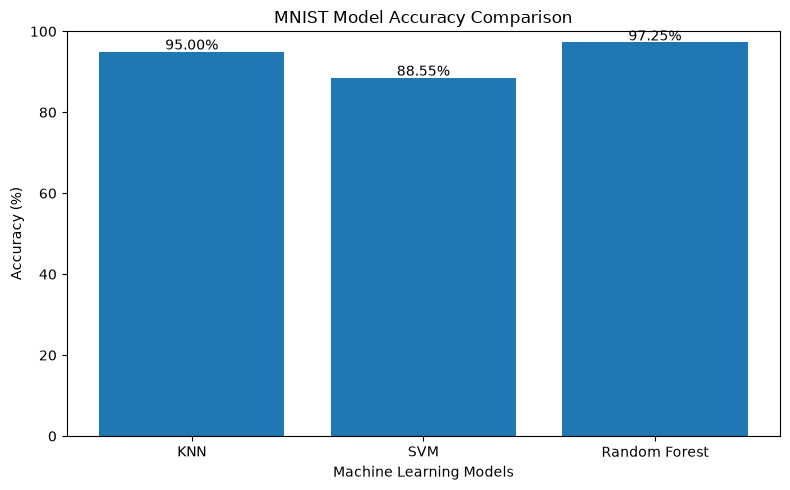

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.title("MNIST Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(comparison["Accuracy (%)"]):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import classification_report

# Generate report for Random Forest
rf_predictions = model.predict(X_test_knn)

print("Random Forest Classification Report:")
print(
    classification_report(
        y_test_knn,
        rf_predictions
    )
)

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       197
           1       0.99      0.99      0.99       225
           2       0.96      0.97      0.97       200
           3       0.98      0.99      0.98       204
           4       0.95      0.96      0.95       195
           5       0.99      0.97      0.98       180
           6       0.98      0.99      0.99       197
           7       0.98      0.96      0.97       208
           8       0.97      0.97      0.97       195
           9       0.94      0.92      0.93       199

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



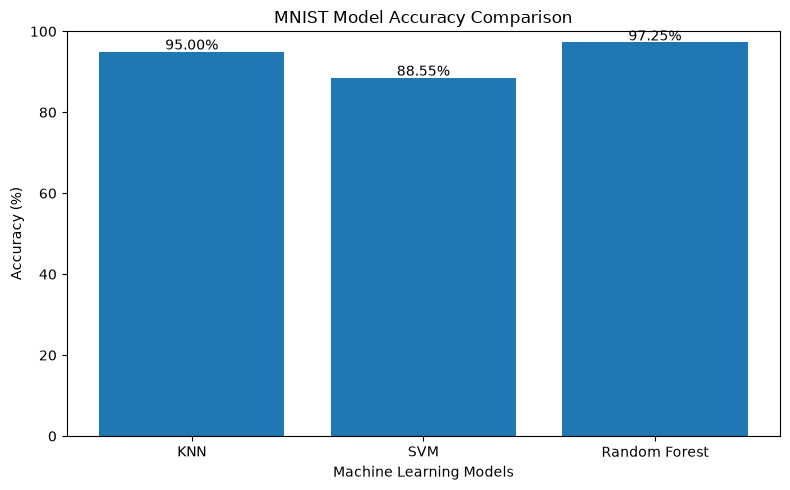

Comparison results and chart saved successfully!


In [22]:
# Save model comparison as a CSV file
comparison.to_csv("model_comparison.csv", index=False)

# Save accuracy chart as an image
plt.figure(figsize=(8, 5))

plt.bar(comparison["Model"], comparison["Accuracy (%)"])
plt.title("MNIST Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(comparison["Accuracy (%)"]):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.savefig("mnist_accuracy_comparison.png", dpi=300)
plt.show()

print("Comparison results and chart saved successfully!")

In [25]:
from sklearn.ensemble import RandomForestClassifier
import joblib

small_model = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

small_model.fit(X_train, y_train)

joblib.dump(
    small_model,
    "mnist_digit_model.pkl",
    compress=3
)

print("Smaller model saved!")

Smaller model saved!


Conclusion

In this project, I developed a handwritten digit recognition system using the MNIST dataset.

I trained and evaluated three machine learning algorithms:

* K-Nearest Neighbors (KNN)
* Support Vector Machine (LinearSVC)
* Random Forest Classifier

Model Comparison

Model	Accuracy
KNN	95.00%
SVM (LinearSVC)	88.55%
Random Forest	97.25%

All three models were evaluated on the same sample of 2,000 test images. Random Forest achieved the highest accuracy of 97.25% in this comparison.

The Random Forest model was also saved and used in a Streamlit application, where users can upload an image of a handwritten digit and receive a prediction.

This project helped me understand data preprocessing, model training, model evaluation, and building a simple machine learning application.

In [26]:
from sklearn.metrics import accuracy_score

small_predictions = small_model.predict(X_test)

small_accuracy = accuracy_score(y_test, small_predictions)

print("Smaller Random Forest Accuracy:", small_accuracy * 100, "%")

Smaller Random Forest Accuracy: 95.57142857142857 %
